Datasets:
(1) Image captioning data set with captions in English

Task 1: Image captioning using VGGNet as encoder and a single hidden layer RNN based
decoder.

Number of nodes in the hidden layer:  50 for Tasks 1

Performance of the system in each task is to be given as BLEU@k scores with k = 1, 2, 3
and 4

In [54]:
import os
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torch.nn.utils.rnn import pad_sequence
from PIL import Image

from torchvision.models import vgg16, VGG16_Weights
from torchvision.transforms import transforms

from collections import Counter
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np

#Installing Glove Embeddings

In [55]:
# !wget -q http://nlp.stanford.edu/data/glove.6B.zip
# !unzip -q glove.6B.zip -d glove/

In [56]:
vgg_16 = vgg16(weights=VGG16_Weights.DEFAULT)

In [57]:
vgg_encoder = vgg_16.features
vgg_encoder.eval()

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (17): Conv2d(256, 512, kernel_si

In [58]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [59]:
class CONFIG:
  def __init__(self):
    self.img_path = '/content/drive/MyDrive/CS6910_Assignment_3/DATASETS/CS6910 Assignment 3/Image captioning dataset/Images/Images'
    self.captions_path = '/content/drive/MyDrive/CS6910_Assignment_3/DATASETS/CS6910 Assignment 3/Image captioning dataset/image_mapping and captions/Team10/captions.txt'
    self.img_names_path = '/content/drive/MyDrive/CS6910_Assignment_3/DATASETS/CS6910 Assignment 3/Image captioning dataset/image_mapping and captions/Team10/image_names.txt'
    self.hidden_layers = 50
    self.batch_size = 32
    self.learning_rate = 1e-4
    # self.glove_path = '/content/glove/glove.6B.100d.txt'
    self.glove_path = '/content/glove/'

config = CONFIG()

In [60]:
class ImageCaptionDataset(Dataset):
  def __init__(self, config, transform=None):
    self.config = config
    self.transform = transform

    with open(config.img_names_path, 'r') as f:
      self.assigned_images = set(line.strip() for line in f if line.strip())

    self.captions_dict = {}
    with open(config.captions_path, 'r') as f:
      for line in f:
        parts = line.strip().split('\t')
        if len(parts) < 2: continue
        img_id_cap = parts[0].split('#')[0].strip()
        caption = parts[1].strip()

        if img_id_cap in self.assigned_images:
          if os.path.exists(os.path.join(config.img_path, img_id_cap)):
            if img_id_cap not in self.captions_dict:
              self.captions_dict[img_id_cap] = []
            self.captions_dict[img_id_cap].append(caption)

    self.img_list = list(self.captions_dict.keys())

  def __len__(self):
    return len(self.img_list)

  def __getitem__(self, idx):
    img_name = self.img_list[idx]
    img_path = os.path.join(config.img_path, img_name)

    image = Image.open(img_path).convert('RGB')

    if self.transform is not None:
      image = self.transform(image)

    captions = self.captions_dict[img_name]
    return image, captions

In [61]:
class EncoderVGG(nn.Module):
  def __init__(self, hidden_dim):
    super().__init__()
    vgg = vgg16(weights=VGG16_Weights.DEFAULT)
    self.feature_extractor = vgg.features
    self.feature_extractor.eval()

    # average pooling to reduce dimensionality
    self.avgpool = vgg.avgpool

    self.fc = nn.Linear(512 * 7 * 7, hidden_dim)

  def forward(self, images):
    with torch.no_grad():
      features = self.feature_extractor(images)
    features = self.avgpool(features)
    features = torch.flatten(features, 1)
    return self.fc(features)

In [62]:
class DecoderRNN(nn.Module):
  def __init__(self, embed_matrix, hidden_dim, vocab_size):
    super().__init__()
    self.embedding = nn.Embedding.from_pretrained(embed_matrix, freeze=True)

    self.rnn = nn.RNN(
        input_size = embed_matrix.shape[1],
        hidden_size = hidden_dim,
        batch_first = True
    )
    self.linear = nn.Linear(hidden_dim, vocab_size)

  def forward(self, features, captions):
    embeddings = self.embedding(captions)

    h0 = features.unsqueeze(0)
    out, _ = self.rnn(embeddings, h0)
    return self.linear(out)

In [63]:
# Standard VGG16 transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Create the dataset variable
dataset = ImageCaptionDataset(config, transform=transform)

from torch.utils.data import random_split

train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
generator = torch.Generator().manual_seed(42)
train_dataset, test_dataset = random_split(dataset, [train_size, test_size], generator=generator)

print(f"Total images: {len(dataset)}")
print(f"Training images: {len(train_dataset)}")
print(f"Testing images: {len(test_dataset)}")

Total images: 2060
Training images: 1648
Testing images: 412


#Creating Vocabulary

In [64]:
def build_vocab(captions_dict, threshold=2):
  counter = Counter()
  for caps in captions_dict.values():
    for cap in caps:
      counter.update(cap.lower().replace('.','').split())

  words = [word for word, cnt in counter.items() if cnt> threshold]
  vocab = {word: i+4 for i, word in enumerate(words)}
  vocab['<pad>'] = 0
  vocab['<start>'] = 1
  vocab['<end>'] = 2
  vocab['<unk>'] = 3

  return vocab

vocab = build_vocab(dataset.captions_dict)
vocab_size = len(vocab)
print(f"Vocabulary Size: {vocab_size}")

Vocabulary Size: 2051


In [65]:
def get_glove_matrix(vocab, glove_path, embed_dim = 100):
  glove_path = os.path.join(glove_path, f'glove.6B.{embed_dim}d.txt')
  weights_matrix = torch.randn((len(vocab), embed_dim))
  found_words = 0
  with open(glove_path, 'r') as f:
    for line in f:
      values = line.split()
      word = values[0]
      if word in vocab:
        vector = torch.tensor([float(x) for x in values[1:]])
        weights_matrix[vocab[word]] = vector
        found_words += 1
  print(f"Found words: {found_words}")
  return weights_matrix

embed_matrix = get_glove_matrix(vocab, config.glove_path, embed_dim=100)

Found words: 2034


In [66]:
def collate_fn(batch):
    # batch is a list of (image_tensor, list_of_5_captions)
    imgs, all_caps = zip(*batch)
    imgs = torch.stack(imgs, 0)

    processed_caps = []
    for cap_list in all_caps:
        # Select the first caption for training[cite: 1]
        raw_cap = cap_list[0]
        tokens = ['<start>'] + raw_cap.lower().replace('.', '').split() + ['<end>']

        # Convert tokens to indices using your vocab
        indices = [vocab.get(token, vocab['<unk>']) for token in tokens]
        processed_caps.append(torch.tensor(indices))

    # Pad sequences to the same length in this batch[cite: 3]
    caps_padded = pad_sequence(processed_caps, batch_first=True, padding_value=vocab['<pad>'])
    return imgs, caps_padded

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=config.batch_size,
    shuffle=True,
    collate_fn=collate_fn
)

In [67]:
# import os
# test_file = '3262386960_14f5d857db.jpg'
# full_path = os.path.join(config.img_path, test_file)

# print(f"Checking path: {full_path}")
# if os.path.exists(full_path):
#     print("✅ File found!")
# else:
#     print("❌ File NOT found. Printing directory contents...")
#     if os.path.exists(config.img_path):
#         print(os.listdir(config.img_path)[:10]) # Print first 10 files
#     else:
#         print(f"Directory itself does not exist: {config.img_path}")

In [68]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize models
torch.manual_seed(42)
encoder = EncoderVGG(hidden_dim=50).to(device)
torch.manual_seed(42)
decoder = DecoderRNN(embed_matrix, hidden_dim=50, vocab_size=len(vocab)).to(device)

# We only train the projection layer of VGG and the Decoder
optimizer = torch.optim.Adam(list(decoder.parameters()) + list(encoder.fc.parameters()), lr=config.learning_rate)
criterion = nn.CrossEntropyLoss(ignore_index=vocab['<pad>'])

# Training
for epoch in range(10): # Adjust epochs as needed
    for imgs, caps in tqdm(train_loader):
        imgs, caps = imgs.to(device), caps.to(device)

        # Forward pass
        features = encoder(imgs)
        # Input to decoder is everything except the last word
        # Target is everything except the first word (<start>)
        outputs = decoder(features, caps[:, :-1])

        loss = criterion(outputs.reshape(-1, len(vocab)), caps[:, 1:].reshape(-1))

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    print(f"Epoch [{epoch+1}/10], Loss: {loss.item():.4f}")

100%|██████████| 52/52 [00:16<00:00,  3.18it/s]


Epoch [1/10], Loss: 7.1966


100%|██████████| 52/52 [00:15<00:00,  3.28it/s]


Epoch [2/10], Loss: 6.9679


100%|██████████| 52/52 [00:16<00:00,  3.25it/s]


Epoch [3/10], Loss: 6.6304


... (10 outputs left out)

100%|██████████| 52/52 [00:16<00:00,  3.24it/s]


Epoch [9/10], Loss: 5.1897


100%|██████████| 52/52 [00:16<00:00,  3.20it/s]


Epoch [10/10], Loss: 5.1917


In [69]:
# Configuration for Experiment 2
LR_2 = 1e-3

# 1. Initialize unique models
torch.manual_seed(42)
encoder_v2 = EncoderVGG(hidden_dim=50).to(device)
torch.manual_seed(42)
decoder_v2 = DecoderRNN(embed_matrix, hidden_dim=50, vocab_size=len(vocab)).to(device)

# 2. Setup Optimizer with the NEW models and NEW learning rate
optimizer_v2 = torch.optim.Adam(
    list(decoder_v2.parameters()) + list(encoder_v2.fc.parameters()),
    lr=LR_2
)
criterion_v2 = nn.CrossEntropyLoss(ignore_index=vocab['<pad>'])

# 3. Training Loop (CRITICAL: Update all variables inside)
for epoch in range(10):
    for imgs, caps in tqdm(train_loader):
        imgs, caps = imgs.to(device), caps.to(device)

        # Use the NEW encoder/decoder
        features = encoder_v2(imgs)
        outputs = decoder_v2(features, caps[:, :-1])

        loss = criterion_v2(outputs.reshape(-1, len(vocab)), caps[:, 1:].reshape(-1))

        optimizer_v2.zero_grad()
        loss.backward()
        optimizer_v2.step()

    print(f"Exp 2 (LR={LR_2}) - Epoch [{epoch+1}/10], Loss: {loss.item():.4f}")

100%|██████████| 52/52 [00:16<00:00,  3.24it/s]


Exp 2 (LR=0.001) - Epoch [1/10], Loss: 5.3712


100%|██████████| 52/52 [00:15<00:00,  3.26it/s]


Exp 2 (LR=0.001) - Epoch [2/10], Loss: 4.6139


100%|██████████| 52/52 [00:16<00:00,  3.12it/s]


Exp 2 (LR=0.001) - Epoch [3/10], Loss: 4.4857


... (10 outputs left out)

100%|██████████| 52/52 [00:18<00:00,  2.84it/s]


Exp 2 (LR=0.001) - Epoch [9/10], Loss: 3.8806


100%|██████████| 52/52 [00:18<00:00,  2.77it/s]


Exp 2 (LR=0.001) - Epoch [10/10], Loss: 3.9171


In [70]:
class DecoderLSTM(nn.Module):
  def __init__(self, embed_matrix, hidden_dim, vocab_size):
    super().__init__()
    self.embedding = nn.Embedding.from_pretrained(embed_matrix, freeze=True)

    # Change to nn.LSTM
    self.lstm = nn.LSTM(
        input_size = embed_matrix.shape[1],
        hidden_size = hidden_dim,
        batch_first = True
    )
    self.linear = nn.Linear(hidden_dim, vocab_size)

  def forward(self, features, captions):
    embeddings = self.embedding(captions)

    # features (batch, 50) becomes h0
    h0 = features.unsqueeze(0)
    # c0 is usually initialized to zeros
    c0 = torch.zeros_like(h0)

    out, _ = self.lstm(embeddings, (h0, c0))
    return self.linear(out)

In [71]:
# Initialize LSTM Decoder
# Ensure embed_matrix was created using your GloVe loader
decoder_lstm = DecoderLSTM(embed_matrix, hidden_dim=50, vocab_size=len(vocab)).to(device)
encoder_lstm = EncoderVGG(hidden_dim=50).to(device) # Separate encoder instance for Task 2

optimizer_lstm = torch.optim.Adam(
    list(decoder_lstm.parameters()) + list(encoder_lstm.fc.parameters()),
    lr=config.learning_rate
)
criterion = nn.CrossEntropyLoss(ignore_index=vocab['<pad>'])

In [72]:
num_epochs = 10 # Adjust based on your 14-minute observation

for epoch in range(num_epochs):
    decoder_lstm.train()
    encoder_lstm.train()
    epoch_loss = 0

    for imgs, caps in tqdm(train_loader):
        imgs, caps = imgs.to(device), caps.to(device)

        # Forward pass
        features = encoder_lstm(imgs)
        # We pass captions except the last token; predict next tokens
        outputs = decoder_lstm(features, caps[:, :-1])

        # Calculate loss
        loss = criterion(outputs.reshape(-1, len(vocab)), caps[:, 1:].reshape(-1))

        optimizer_lstm.zero_grad()
        loss.backward()
        optimizer_lstm.step()

        epoch_loss += loss.item()

    print(f"Task 2 (LSTM) - Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss/len(train_loader):.4f}")

100%|██████████| 52/52 [00:27<00:00,  1.87it/s]


Task 2 (LSTM) - Epoch [1/10], Loss: 7.5061


100%|██████████| 52/52 [00:27<00:00,  1.92it/s]


Task 2 (LSTM) - Epoch [2/10], Loss: 7.3523


100%|██████████| 52/52 [00:26<00:00,  1.97it/s]


Task 2 (LSTM) - Epoch [3/10], Loss: 7.1268


... (10 outputs left out)

100%|██████████| 52/52 [00:26<00:00,  2.00it/s]


Task 2 (LSTM) - Epoch [9/10], Loss: 5.3066


100%|██████████| 52/52 [00:26<00:00,  1.93it/s]

Task 2 (LSTM) - Epoch [10/10], Loss: 5.2154


In [73]:
def generate_caption(encoder, decoder, image, vocab, max_len=20, is_lstm=True):
    result_caption = []

    with torch.no_grad():
        feature = encoder(image.unsqueeze(0).to(device)) # (1, 50)

        # Initial hidden state
        h = feature.unsqueeze(0) # (1, 1, 50)
        c = torch.zeros_like(h) if is_lstm else None

        # Start token
        word_idx = torch.tensor([vocab['<start>']]).to(device)

        for _ in range(max_len):
            embeddings = decoder.embedding(word_idx).unsqueeze(0) # (1, 1, embed_dim)

            if is_lstm:
                output, (h, c) = decoder.lstm(embeddings, (h, c))
            else:
                output, h = decoder.rnn(embeddings, h)

            output = decoder.linear(output.squeeze(0))
            predicted_idx = output.argmax(1).item()

            if predicted_idx == vocab['<end>']:
                break

            # Convert index to word
            for word, idx in vocab.items():
                if idx == predicted_idx:
                    result_caption.append(word)
                    break

            word_idx = torch.tensor([predicted_idx]).to(device)

    return ' '.join(result_caption)

--- TASK 1: RNN Evaluation (Test Set) ---
Calculating BLEU scores for 412 images...


100%|██████████| 412/412 [00:12<00:00, 32.51it/s]



Results:
BLEU@1: 0.1222
BLEU@2: 0.0247
BLEU@3: 0.0155
BLEU@4: 0.0117

--- TASK 2: LSTM Evaluation (Test Set) ---
Calculating BLEU scores for 412 images...


100%|██████████| 412/412 [00:08<00:00, 48.35it/s]



Results:
BLEU@1: 0.2341
BLEU@2: 0.0597
BLEU@3: 0.0489
BLEU@4: 0.0431

QUALITATIVE RESULTS: 5 TRAINING EXAMPLES (LSTM)


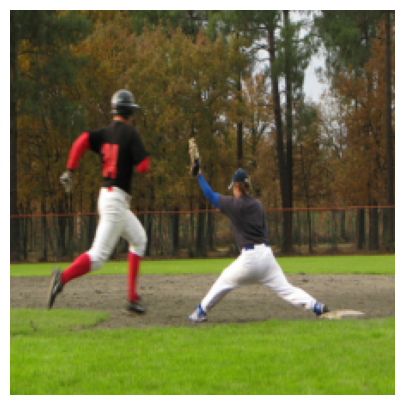

Example 1
Generated (LSTM): a a a
Ground Truths:
  1. A runner heading toward a base while the baseman tries to tag him out .
  2. one baseball player running toward a base with another waiting on the base
  3. These two people are in baseball uniforms , making a play at base .
  4. Two men playing baseball with the one in the black and red jersey running toward base .
  5. Two people playing baseball .
--------------------------------------------------


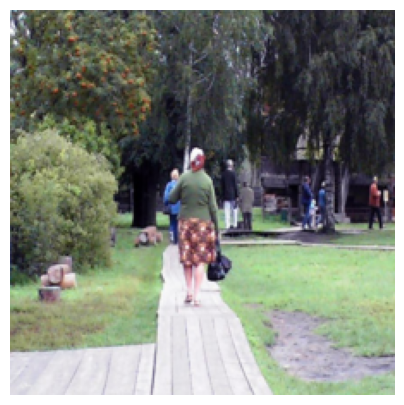

Example 2
Generated (LSTM): a a a
Ground Truths:
  1. A woman in a skirt walks down a path .
  2. a woman walks on boards .
  3. A woman with a scarf on her head walks down a wooden boardwalk .
  4. Several people in a park walking on a low wooden boardwalk .
  5. The woman wearing the brown skirt is carrying a black bag along a wooden walkway .
--------------------------------------------------


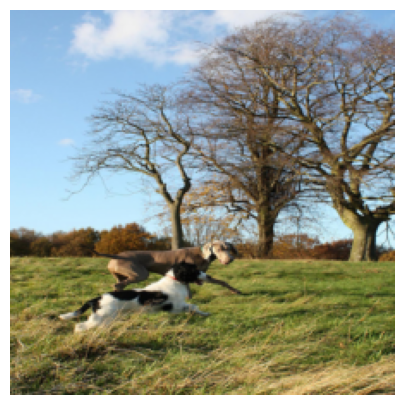

Example 3
Generated (LSTM): a a a
Ground Truths:
  1. one large brown dog running alongside a black and white dog .
  2. Two dogs are running on the grass in front of the trees .
  3. Two dogs are running through a grassy area near tall trees .
  4. Two dogs running in the grass .
  5. Two dog with trees in the background .
--------------------------------------------------


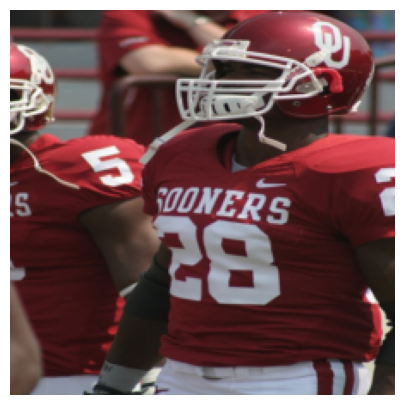

Example 4
Generated (LSTM): a a a
Ground Truths:
  1. A football player is in a red and white uniform Sooners # 28 .
  2. A large football player in a red uniform
  3. A man in a red football uniform and helmet looks to the left .
  4. The Oklahoma football player watches the game from the sidelines .
  5. This football team wears red shirts and red helmets .
--------------------------------------------------


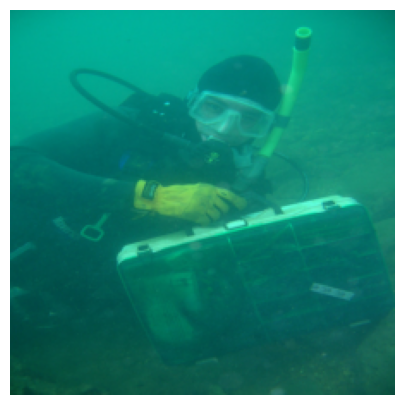

Example 5
Generated (LSTM): a a a
Ground Truths:
  1. A man in a scuba suit holds a box .
  2. A man scuba diving underwater .
  3. A yellow gloved diver with a snorkel and mask swims underwater carrying a box with a handle .
  4. Scuba diver submerged in water .
  5. The scuba diver is underwater .
--------------------------------------------------

QUALITATIVE RESULTS: 5 TEST EXAMPLES (LSTM)


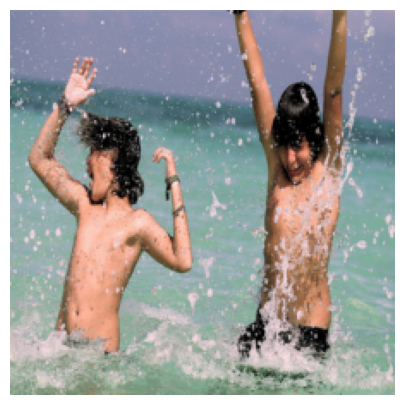

Example 1
Generated (LSTM): a a a
Ground Truths:
  1. Two boys splashing each other in the ocean .
  2. Two boys splashing in the surf .
  3. Two boys splash in the big ocean .
  4. Two children splashing in the ocean .
  5. Two shirtless young people playing in the water .
--------------------------------------------------


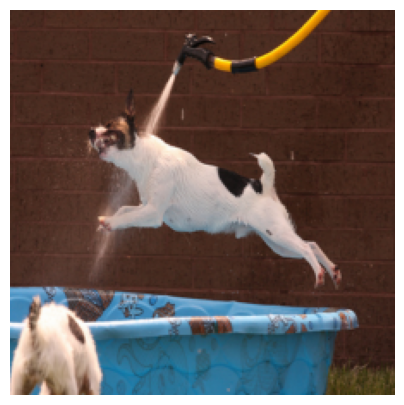

Example 2
Generated (LSTM): a a a
Ground Truths:
  1. A dog is being squirted with a hose as it jumps into a paddling pool .
  2. A dog is hosed as it jumps into a kiddie pool .
  3. A terrier is sprayed by a hose while jumping in a pool .
  4. A white dog with black patches runs jumps through a spray from a hose into a blue plastic wading pool .
  5. While one white dog is outside the pool , another white dog with a black spot on its back is jumping into a plastic swimming pool while getting sprayed by a garden hose .
--------------------------------------------------


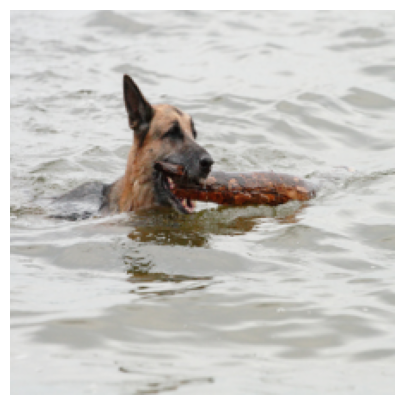

Example 3
Generated (LSTM): a a a
Ground Truths:
  1. A brown dog swims and carries a brown object .
  2. A dog swims through the water while holding a stick in its mouth .
  3. A German Shephard carries a small log in the water .
  4. Dog is swimming through water with a piece of wood in its mouth .
  5. German Shepherd retrieving large stick from water
--------------------------------------------------


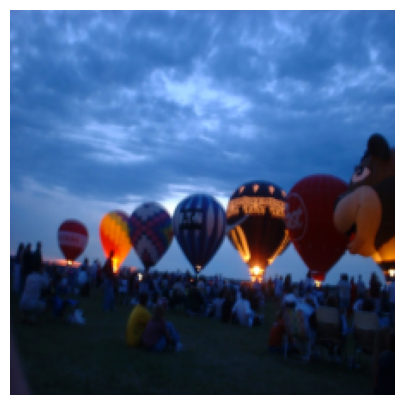

Example 4
Generated (LSTM): a a a
Ground Truths:
  1. A crowd watching air balloons at night .
  2. A group of hot air balloons lit up at night .
  3. People are watching hot air balloons in the park .
  4. People watching hot air balloons .
  5. Seven large balloons are lined up at nighttime near a crowd .
--------------------------------------------------


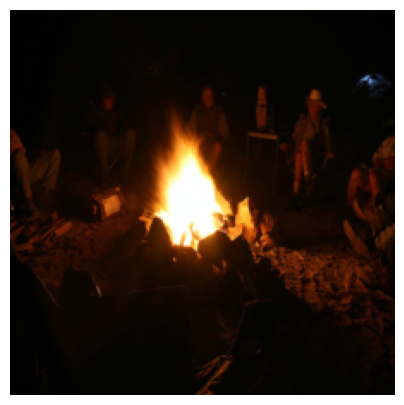

Example 5
Generated (LSTM): a a a
Ground Truths:
  1. A group of people sit around a blazing fire at night .
  2. A large campfire at night with several people sitting around it .
  3. People are clustered around a bonfire at night .
  4. People sitting around a campfire at night .
  5. Several people are sitting around a fire at night .
--------------------------------------------------


In [74]:
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
import warnings
import matplotlib.pyplot as plt
import random
warnings.filterwarnings('ignore') # Hides NLTK warnings for short sentences

# --- 1. DEFINE FUNCTIONS FIRST ---

def calculate_bleu_scores(encoder, decoder, dataset, vocab, is_lstm=False):
    bleu1, bleu2, bleu3, bleu4 = 0.0, 0.0, 0.0, 0.0
    smoother = SmoothingFunction().method1

    encoder.eval()
    decoder.eval()

    print(f"Calculating BLEU scores for {len(dataset)} images...")

    for i in tqdm(range(len(dataset))):
        img, ground_truths = dataset[i]

        # Generate prediction
        pred_sentence = generate_caption(encoder, decoder, img, vocab, is_lstm=is_lstm)
        predicted_tokens = pred_sentence.split()

        # Format the 5 ground truths
        reference_tokens = [gt.lower().replace('.', '').split() for gt in ground_truths]

        # Calculate scores
        bleu1 += sentence_bleu(reference_tokens, predicted_tokens, weights=(1, 0, 0, 0), smoothing_function=smoother)
        bleu2 += sentence_bleu(reference_tokens, predicted_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=smoother)
        bleu3 += sentence_bleu(reference_tokens, predicted_tokens, weights=(0.33, 0.33, 0.33, 0), smoothing_function=smoother)
        bleu4 += sentence_bleu(reference_tokens, predicted_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smoother)

    n = len(dataset)
    print(f"\nResults:")
    print(f"BLEU@1: {bleu1/n:.4f}")
    print(f"BLEU@2: {bleu2/n:.4f}")
    print(f"BLEU@3: {bleu3/n:.4f}")
    print(f"BLEU@4: {bleu4/n:.4f}")
    return (bleu1/n, bleu2/n, bleu3/n, bleu4/n)

def display_examples(encoder, decoder, dataset, vocab, is_lstm=False, num_examples=5):
    encoder.eval()
    decoder.eval()

    # Pick random indices
    indices = random.sample(range(len(dataset)), num_examples)

    for i, idx in enumerate(indices):
        img_tensor, ground_truths = dataset[idx]

        # Un-normalize the image for plotting
        img_plot = img_tensor.permute(1, 2, 0).cpu().numpy()
        img_plot = np.clip((img_plot * [0.229, 0.224, 0.225]) + [0.485, 0.456, 0.406], 0, 1)

        # Generate prediction
        prediction = generate_caption(encoder, decoder, img_tensor, vocab, is_lstm=is_lstm)

        # Plot
        plt.figure(figsize=(5, 5))
        plt.imshow(img_plot)
        plt.axis('off')
        plt.show()

        print(f"Example {i+1}")
        print(f"Generated ({'LSTM' if is_lstm else 'RNN'}): {prediction}")
        print("Ground Truths:")
        for j, gt in enumerate(ground_truths):
            print(f"  {j+1}. {gt}")
        print("-" * 50)


# --- 2. EXECUTE EVALUATIONS ---

# Quantitative BLEU Scores
print("\n--- TASK 1: RNN Evaluation (Test Set) ---")
calculate_bleu_scores(encoder, decoder, test_dataset, vocab, is_lstm=False)

print("\n--- TASK 2: LSTM Evaluation (Test Set) ---")
calculate_bleu_scores(encoder_lstm, decoder_lstm, test_dataset, vocab, is_lstm=True)

# Qualitative Examples (RNN)
print("\n" + "="*50)
print("QUALITATIVE RESULTS: 5 TRAINING EXAMPLES (RNN)")
print("="*50)
display_examples(encoder, decoder, train_dataset, vocab, is_lstm=False, num_examples=5)

print("\n" + "="*50)
print("QUALITATIVE RESULTS: 5 TEST EXAMPLES (RNN)")
print("="*50)
display_examples(encoder, decoder, test_dataset, vocab, is_lstm=False, num_examples=5)

# Qualitative Examples (LSTM)
print("\n" + "="*50)
print("QUALITATIVE RESULTS: 5 TRAINING EXAMPLES (LSTM)")
print("="*50)
display_examples(encoder_lstm, decoder_lstm, train_dataset, vocab, is_lstm=True, num_examples=5)

print("\n" + "="*50)
print("QUALITATIVE RESULTS: 5 TEST EXAMPLES (LSTM)")
print("="*50)
display_examples(encoder_lstm, decoder_lstm, test_dataset, vocab, is_lstm=True, num_examples=5)

Displaying RNN Examples:


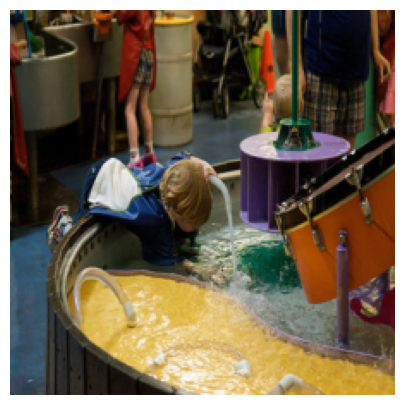

Example 1
Generated (RNN): a a a a a a a a a a a a a a a a a a a a
Ground Truths:
  1. A child leans over a vat .
  2. A child playing with water in a children 's discovery museum .
  3. A child plays in a multi-colored fountain .
  4. A little child playing in water with a hose .
  5. A young child is playing in a water tank with toys .
--------------------------------------------------


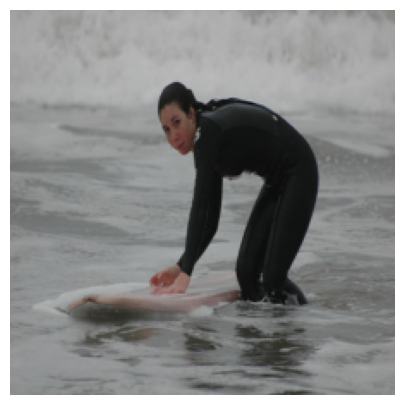

Example 2
Generated (RNN): a a a a a a a a a a a a a a a a a a a a
Ground Truths:
  1. a female surfer
  2. A woman in a wetsuit aids a fish in need of attention .
  3. A woman in a wetsuit in surfing in the ocean .
  4. A young woman wearing a wetsuit is in the ocean .
  5. The surfer is wearing a black body suit while picking up her board .
--------------------------------------------------


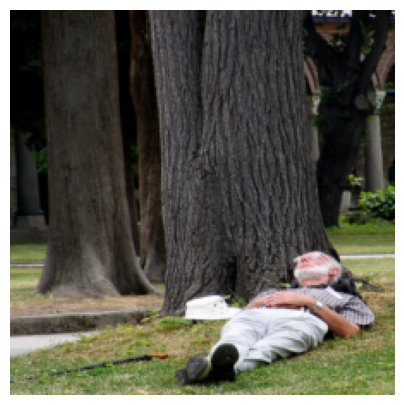

Example 3
Generated (RNN): a a a a a a a a a a a a a a a a a a a a
Ground Truths:
  1. A bearded man laying on his back under a large tree .
  2. A grey bearded man is sleeping under a tree .
  3. A man laying in the grass under a tree .
  4. A well dressed man with a cane and a beard , sleeping under a tree in a park .
  5. A white haired man lays down his cane and hat and rests next to a tree .
--------------------------------------------------


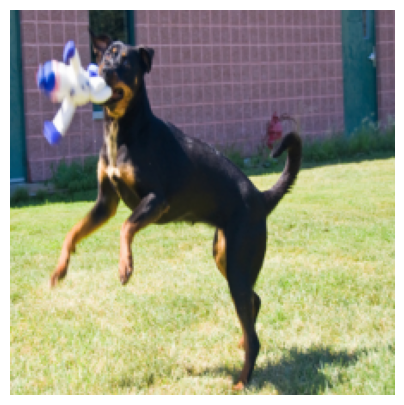

Example 4
Generated (RNN): a a a a a a a a a a a a a a a a a a a a
Ground Truths:
  1. A black and tan dog plays with a stuffed toy .
  2. A black dog plays with a white and blue colored stuffed animal .
  3. A doberman jumping in the air playing with a toy
  4. A dog playing with its toy .
  5. Black dog playing with a white and blue toy .
--------------------------------------------------


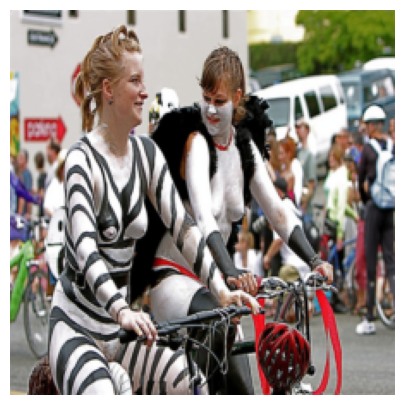

Example 5
Generated (RNN): a a a a a a a a a a a a a a a a a a a a
Ground Truths:
  1. Two ladies are wearing nothing except body paint and riding on bicycles in a street fair .
  2. Two nude women painted black and white are riding bicycles on the road .
  3. Two painted women ride bicycles on the street with onlookers nearby .
  4. Two woman wearing body paint ride bikes through a crowd .
  5. Two women in costume ride bikes .
--------------------------------------------------
